# Industry momentum: Research exercise

**Research question.** Does investing in the previous month's best-performing US industry portfolio outperform a monthly rebalanced equal-weight portfolio of ten industries?

This is an **exploratory, in-sample analysis**, not a validated trading strategy. We inspect winner persistence, calculate strategy returns, and examine performance across historical periods. Results exclude trading costs. The pre/post-2000 split was motivated by the full-sample plot and is **not** an untouched out-of-sample test.

## 1. Setup and load the data

**Source:** Kenneth R. French Data Library, *10 Industry Portfolios — Daily*. Use the downloaded `10_Industry_Portfolios_Daily.csv` in the same directory as this notebook. The file contains explanatory text and multiple tables. We use the **value-weighted daily returns** table. Daily returns are recorded in **percent**, and missing values are represented by `-99.99` or `-999`.

In [170]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

Inspect the first lines of the csv file

In [172]:
with open("10_Industry_Portfolios_Daily.csv", "r") as f:
    for i in range(25):
        print(f.readline().strip())

This file was created using the 202609 CRSP database.
It contains value- and equal-weighted returns for 10 industry portfolios.

The portfolios are constructed at the end of June.

Missing data are indicated by -99.99 or -999.


Average Value Weighted Returns -- Daily
,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
19260701,   0.02,  -0.28,  -0.23,   0.57,  -0.21,  -0.02,  -0.01,   0.97,   0.61,   0.20
19260702,   0.29,   1.07,   0.81,   0.64,   0.36,   0.26,   0.01,   0.13,   0.47,   0.10
19260706,   0.24,   0.72,   0.22,   0.17,   0.47,   0.17,  -0.23,   0.23,   0.73,  -0.18
19260707,   0.27,   0.06,   0.23,  -0.04,  -0.10,   0.32,  -0.59,   0.33,   0.17,   0.16
19260708,   0.69,   0.05,   0.15,   0.12,   0.35,   0.40,  -0.36,   0.91,  -0.20,   0.39
19260709,  -0.39,  -1.15,  -1.10,  -1.60,  -0.73,   0.21,   0.40,  -0.28,  -0.74,  -0.25
19260710,   0.67,   1.23,   0.78,   0.65,   0.39,   0.07,   0.52,  -0.17,   0.55,   0.55
19260712,   0.27,   0.78,   0.25,  -1.27,   0.03

The first 8 rows are info. Moreover, it seems that the data contains more than one table:
"It contains value- and equal-weighted returns"
And we see that the first table is "Average Value Weighted Returns -- Daily"
So we look for "Average Equal Weighted Returns"

In [23]:
with open("10_Industry_Portfolios_Daily.csv") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if "Average Equal Weighted Returns" in line:
        print(i, line.strip())
for i, line in enumerate(lines):
    if "Average Value Weighted Returns" in line:
        print(i, line.strip())

26350 Average Equal Weighted Returns -- Daily
8 Average Value Weighted Returns -- Daily


The second table starts at row 26350. The first table starts at row 8.
The numbering starts from 0.
So we skip the first 8 lines (0,...,7): skiprows=8.
and we want the lines until 26349: unclear how to count but thorugh a few trials we get that we have to keep 26339 rows.

In [173]:
df = pd.read_csv(
    "10_Industry_Portfolios_Daily.csv",
    skiprows=9,
    nrows=26338
)
df.head()

,Unnamed: 0,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
0,19260701,0.02,-0.28,-0.23,0.57,-0.21,-0.02,-0.01,0.97,0.61,0.20
1,19260702,0.29,1.07,0.81,0.64,0.36,0.26,0.01,0.13,0.47,0.10
2,19260706,0.24,0.72,0.22,0.17,0.47,0.17,-0.23,0.23,0.73,-0.18
3,19260707,0.27,0.06,0.23,-0.04,-0.10,0.32,-0.59,0.33,0.17,0.16
4,19260708,0.69,0.05,0.15,0.12,0.35,0.40,-0.36,0.91,-0.20,0.39


In [60]:
df.tail()

,Unnamed: 0,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
26333,20260924,-0.49,-0.79,-0.76,0.56,0.19,0.59,-0.61,0.57,-0.85,-0.12
26334,20260925,-0.08,-0.94,1.11,-0.83,0.53,-0.22,0.28,0.47,-0.02,0.59
26335,20260928,-0.04,-3.42,-0.86,0.17,-0.93,-0.63,-0.61,0.33,-0.64,-0.99
26336,20260929,-0.38,-1.06,0.60,-0.82,-0.21,-1.16,-0.16,-0.28,0.72,-0.29
26337,20260930,-1.20,0.05,-1.03,0.27,0.46,-0.07,-0.41,-1.24,-0.79,-1.13


Inspect the dataframe:
* number of rows and columns
* names of columns
* data types

In [174]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26338 entries, 0 to 26337
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  26338 non-null  int64  
 1   NoDur       26338 non-null  float64
 2   Durbl       26338 non-null  float64
 3   Manuf       26338 non-null  float64
 4   Enrgy       26338 non-null  float64
 5   HiTec       26338 non-null  float64
 6   Telcm       26338 non-null  float64
 7   Shops       26338 non-null  float64
 8   Hlth        26338 non-null  float64
 9   Utils       26338 non-null  float64
 10  Other       26338 non-null  float64
dtypes: float64(10), int64(1)
memory usage: 2.2 MB


No missing values but they used -99.99 and -999 for missing values

Give the Unnamed column = Date, the date name

In [175]:
df = df.rename(columns={"Unnamed: 0": "Date"})
df["Date"] = pd.to_datetime(df["Date"].astype(str), format="%Y%m%d")
df = df.set_index("Date").sort_index()
df.head()

,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
Date,,,,,,,,,,
1926-07-01,0.02,-0.28,-0.23,0.57,-0.21,-0.02,-0.01,0.97,0.61,0.20
1926-07-02,0.29,1.07,0.81,0.64,0.36,0.26,0.01,0.13,0.47,0.10
1926-07-06,0.24,0.72,0.22,0.17,0.47,0.17,-0.23,0.23,0.73,-0.18
1926-07-07,0.27,0.06,0.23,-0.04,-0.10,0.32,-0.59,0.33,0.17,0.16
1926-07-08,0.69,0.05,0.15,0.12,0.35,0.40,-0.36,0.91,-0.20,0.39


In [176]:
df = df.replace([-99.99, -999], float("nan"))

In [177]:
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
DatetimeIndex: 26338 entries, 1926-07-01 to 2026-09-30
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   NoDur   26338 non-null  float64
 1   Durbl   26338 non-null  float64
 2   Manuf   26338 non-null  float64
 3   Enrgy   26338 non-null  float64
 4   HiTec   26338 non-null  float64
 5   Telcm   26338 non-null  float64
 6   Shops   26338 non-null  float64
 7   Hlth    26338 non-null  float64
 8   Utils   26338 non-null  float64
 9   Other   26338 non-null  float64
dtypes: float64(10)
memory usage: 2.2 MB


NoDur    0
Durbl    0
Manuf    0
Enrgy    0
HiTec    0
Telcm    0
Shops    0
Hlth     0
Utils    0
Other    0
dtype: int64

Pandas understands partial dates so we can do:
* df.loc["2020"]                  # All data from 2020
* df.loc["2020", "HiTec"]         # HiTec data from 2020
* df.loc["2020-03"]               # March 2020
* df.loc["2020-01":"2020-06"]     # January through June 2020
* df.loc["2020", ["HiTec", "Enrgy"]]  # Two industries

<Axes: xlabel='Date'>

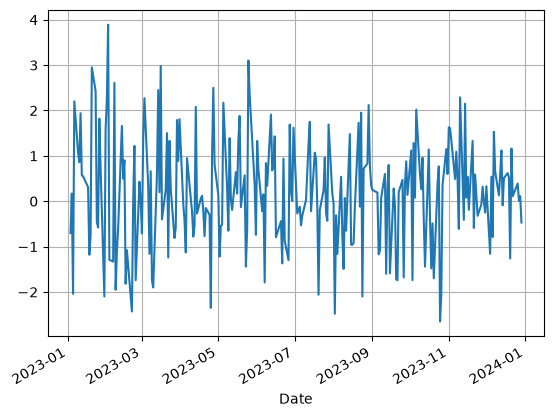

In [178]:
df.loc["2023", "HiTec"].plot(grid=True)

## 2. Do monthly winners repeat?

Let $W_t$ be the industry with the highest return in month $t$. A repetition occurs when $W_t=W_{t-1}$.

Strategy:
* Compute monthly performance for each industry
* Each month: Identify best-performers.
* Next month: Compare performances

## 2. Construct monthly returns

Daily simple returns compound: $R_m=\prod_{d\in m}(1+r_d)-1$. Convert the source's percentage returns into decimals **before** compounding (the dataset expresses returns in percentages (e.g. 2 rather than 0.02), so we first divide by 100). Month-end labels identify the calendar month, not necessarily a trading day.

.resample("ME"): groups observations by calendar month.
.prod(): multiplies the daily growth factors within each month.

In [179]:
monthly = (1 + df / 100).resample("ME").prod() - 1
monthly.head()

,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
Date,,,,,,,,,,
1926-07-31,0.014326,0.155957,0.047293,-0.011582,0.029136,0.008246,0.001029,0.018400,0.070369,0.021095
1926-08-31,0.039851,0.036903,0.028235,0.034508,0.027005,0.021708,-0.007123,0.041969,-0.016931,0.043547
1926-09-30,0.011290,0.050181,0.011470,-0.033716,-0.003983,0.024094,0.002088,0.006946,0.020454,0.003020
1926-10-31,-0.012316,-0.083809,-0.036667,-0.007698,-0.045875,-0.001250,-0.022993,-0.005844,-0.032651,-0.028476
1926-11-30,0.052481,-0.001617,0.042426,0.000277,0.046917,0.016482,0.064661,0.054346,0.044239,0.021393


Let $W_t$ be the industry with the highest return in month $t$. A repetition occurs when $W_t=W_{t-1}$. This is a deliberately coarse measure of momentum: an industry can outperform again without finishing first.

In [180]:
winners = monthly.idxmax(axis=1) # idxmax = label corresponding to largest value
N = len(winners)
winners.head()

Date
1926-07-31    Durbl
1926-08-31    Other
1926-09-30    Durbl
1926-10-31    Telcm
1926-11-30    Shops
Freq: ME, dtype: str

In [181]:
same_winner = winners == winners.shift(-1)  # same_winner[t] = 1 iff winners[t] = winners[t-1]
observed = same_winner.sum()  # mean over all rows. Entries are 0 or 1. The mean tells us how often  the winner stays the winner
print('Number of months:', N)
print('Number of repeated winners:', observed)


Number of months: 1203
Number of repeated winners: 176


### An i.i.d. winners benchmark

Assume each monthly winner $W_t$ is independent and has the same distribution over time, with $P(W_t=i)=p_i$. Then the probability of a repetition is $P=\sum_i p_i^2$, and for $X$ repetitions across $N-1$ transitions,

$$E[X]=(N-1)P.$$

Repetition indicators for adjacent months **need not be independent**: they share one winner. In fact,

$$\mathrm{Var}(X)=(N-1)P(1-P)+2(N-2)\left(\sum_i p_i^3-P^2\right).$$

We estimate $p_i$ by the observed frequency with which industry $i$ wins. The following calculation is a **descriptive plug-in normal approximation**, *not a fully calibrated p-value*, because the probabilities are estimated from the same sequence and may change over the century.

In [183]:
p = winners.value_counts(normalize=True)
p0 = (p**2).sum()
Q = (p**3).sum()
expected = (N-1)*p0
variance_known_p = (N-1)*p0*(1-p0) + 2*(N-2)*(Q-p0**2)
z_descriptive = (observed - expected) / np.sqrt(variance_known_p)
naive_tail = norm.sf(z_descriptive)

print(p)
print(f"Expected repetitions (plug-in): {expected:.1f}")
print(f"Standard deviation (treating p as known): {np.sqrt(variance_known_p):.2f}")
print(f"Descriptive z-score: {z_descriptive:.2f}")
print(f"Uncalibrated normal tail area: {naive_tail:.4g}")

Enrgy    0.176226
Durbl    0.157107
Hlth     0.128013
HiTec    0.127182
Utils    0.117207
Telcm    0.110557
Shops    0.073982
Other    0.046550
NoDur    0.034913
Manuf    0.028263
Name: proportion, dtype: float64
Expected repetitions (plug-in): 149.0
Standard deviation (treating p as known): 11.60
Descriptive z-score: 2.33
Uncalibrated normal tail area: 0.009849


**Interpretation.** An excess of repetitions over the i.i.d. benchmark is a potential sign of temporal structure. However, industry winning probabilities are unlikely to be constant over 1926–2026. Rejecting a global i.i.d. model would not by itself establish a tradable momentum effect. We therefore move from repetition counts to **realised next-month returns**.

## 4. A simple one-month momentum strategy

**Rule:** At the end of month $t$, identify that month's best-performing industry and hold it during month $t+1$. No future information is used to choose the industry. **Benchmark:** hold all 10 industries in equal weights, rebalanced at each month-end.

Both return series begin in the second month, since the first month only supplies the initial signal. Strategy results are **gross of fees, turnover costs, taxes, and slippage**.

In [187]:
strategy_returns = []

for t in range(N-1):
    winner = winners.iloc[t]
    strategy_returns.append(monthly[winner].iloc[t+1])

Convert the list into a panda series to associate each return with the month

In [188]:
strategy_returns = pd.Series(
    strategy_returns,
    index=monthly.index[1:]     # strategy_returns[0] is the return of the second month, the shift [1:] accounts for that 
)

If we invest equally in each industry the return for the month is 1/10 (r1+...+r10) = mean(r_i)

In [189]:
benchmark_returns = []

for t in range(N-1):
    benchmark_returns.append(monthly.iloc[t+1].mean())

benchmark_returns = pd.Series(
    benchmark_returns,
    index=monthly.index[1:]
)

Compare the **arithmetic** means:

In [193]:
strategy_mean = strategy_returns.mean()
benchmark_mean = benchmark_returns.mean()
excess_returns = strategy_returns - benchmark_returns
ex_returns_mean = excess_returns.mean()
print('Average monthly strategy return:', strategy_mean)
print('Average monthly benchmark return:', benchmark_mean)
print('Average monthly excess return:', ex_returns_mean)

Average monthly strategy return: 0.012374455162349364
Average monthly benchmark return: 0.010049514369537871
Average monthly excess return: 0.0023249407928114937


### Exploratory test of arithmetic excess returns

The average monthly excess return answers whether the strategy tends to outperform **in a month**. It is not the same as a comparison of compounded growth. Under a *simplifying* assumption that monthly excess returns are i.i.d. with finite variance, we can estimate the standard error of the sample mean as $s/\sqrt{n}$ and perform a one-sided normal approximation to $H_0:E[D_t]=0$ against $H_1:E[D_t]>0$.

This is **illustrative only**: serial correlation, the exploratory choice of strategy, and multiple testing can invalidate the nominal significance level.

In [194]:
n_excess = len(excess_returns)
se_iid = excess_returns.std() / np.sqrt(n_excess)
z_excess = excess_returns.mean() / se_iid
print(f"Monthly excess-return SD: {excess_returns.std():.4%}")
print(f"IID standard error of monthly mean: {se_iid:.4%}")
print(f"Illustrative one-sided normal p-value: {norm.sf(z_excess):.4f}")

Monthly excess-return SD: 4.1085%
IID standard error of monthly mean: 0.1185%
Illustrative one-sided normal p-value: 0.0249


## Cumulative wealth performance

Starting from 1, wealth at time $t$ is $V_t=\prod_{s=1}^t(1+r_s)$. A **logarithmic plot axis** changes only the display, not the wealth itself.

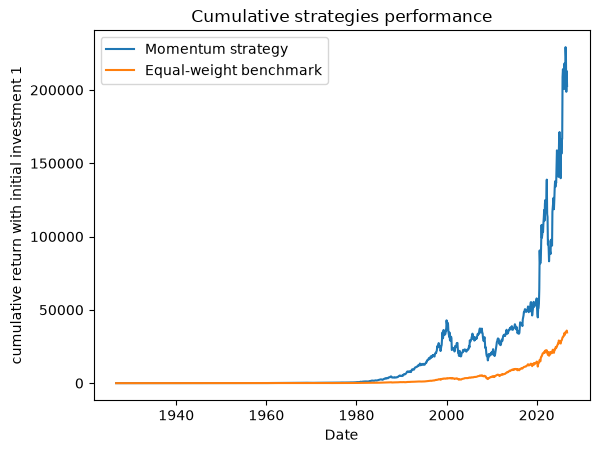

In [ ]:
strategy_wealth = (1 + strategy_returns).cumprod()
benchmark_wealth = (1 + benchmark_returns).cumprod()

import matplotlib.pyplot as plt

plt.plot(strategy_wealth, label = "Momentum strategy")
plt.plot(benchmark_wealth, label = "Equal-weight benchmark")
plt.xlabel("Date")
plt.ylabel("cumulative return with initial investment 1")
plt.title("Cumulative strategies performance")
plt.legend()
plt.show()

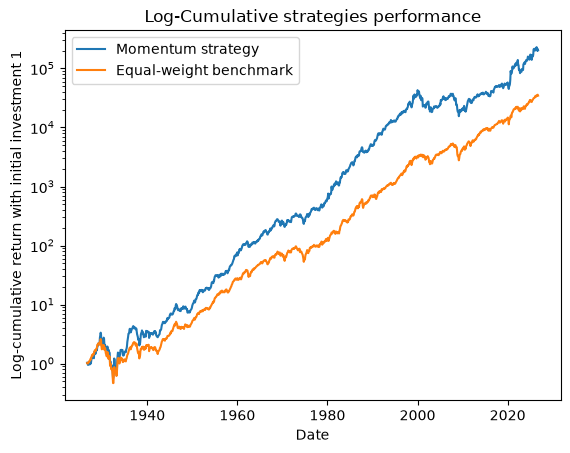

In [ ]:
plt.plot(strategy_wealth, label = "Momentum strategy")
plt.plot(benchmark_wealth, label = "Equal-weight benchmark")
plt.yscale("log")
plt.xlabel("Date")
plt.ylabel("Log-cumulative return with initial investment 1")
plt.title("Log-Scale strategies performance")
plt.legend()
plt.show()

The **log relative wealth** $\log(V_{strategy}/V_{benchmark})$ helps identify *when* relative wealth is gained or lost. An upward slope signals relative outperformance during that period; a downward slope signals relative underperformance.

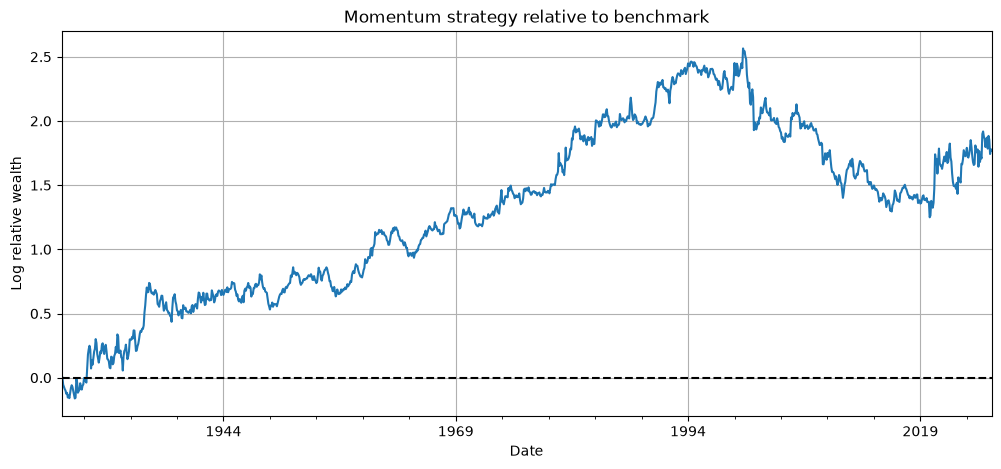

In [164]:
relative_wealth = strategy_wealth / benchmark_wealth

np.log(relative_wealth).plot(figsize=(12, 5), grid=True)
plt.axhline(0, color="black", linestyle="--")
plt.ylabel("Log relative wealth")
plt.title("Momentum strategy relative to benchmark")
plt.show()

**Visual observation:** Relative wealth rose until roughly 1999, then generally declined. The split at 2000 below is therefore a **post-hoc descriptive comparison**, not an independent validation.

### Comparison of subperiods 1926-1999 and 2000-2026

## 6. Pre/post-2000 performance summary

- **CAGR:** geometric annual growth rate over the period.
- **Annualised volatility:** monthly sample standard deviation multiplied by $\sqrt{12}$ (conventional approximation).
- **CAGR / volatility:** a descriptive ratio; **not** the standard Sharpe ratio, which uses excess returns over the risk-free rate.

In [195]:
def performance_stats(r):
    ann_return = (1 + r).prod()**(12 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(12)
    sharpe = ann_return / ann_vol
    wealth = (1 + r).cumprod()
    max_drawdown = ((wealth / wealth.cummax()) - 1).min()
    return pd.Series({
        "Annualized return": ann_return,
        "Annualized volatility": ann_vol,
        "CAGR / volatility": sharpe,
    })

In [196]:
pre2000_strategy = strategy_returns.loc[: "1999-12-31"]
pre2000_benchmark = benchmark_returns.loc[: "1999-12-31"]

post2000_strategy = strategy_returns.loc["2000-01-01" :]
post2000_benchmark = benchmark_returns.loc["2000-01-01" :]

In [197]:
summary = pd.DataFrame({
    "Strategy pre-2000": performance_stats(pre2000_strategy),
    "Benchmark pre-2000": performance_stats(pre2000_benchmark),
    "Strategy post-2000": performance_stats(post2000_strategy),
    "Benchmark post-2000": performance_stats(post2000_benchmark),
})
print(summary)

                       Strategy pre-2000  Benchmark pre-2000  \
Annualized return               0.156357            0.116655   
Annualized volatility           0.229971            0.187760   
CAGR / volatility               0.679898            0.621297   

                       Strategy post-2000  Benchmark post-2000  
Annualized return                0.059813             0.091855  
Annualized volatility            0.235430             0.149131  
CAGR / volatility                0.254060             0.615933  
